# TP2 · Ejercicio 1 — Reconocimiento de comandos de voz con CRNN

Aprendizaje Automático II · TUIA · FCEIA - UNR · Grupo 9

Este notebook resuelve el Ejercicio 1. Una red convolucional-recurrente (CRNN)
clasifica comandos de voz de un segundo del dataset Google Speech Commands v2.

El esquema es *many-to-one*:

1. El audio pasa a un espectrograma de Mel.
2. El espectrograma se corta en ventanas temporales con solapamiento.
3. Una CNN comprime cada ventana a un vector.
4. Una RNN recorre la secuencia de vectores.
5. Una capa densa clasifica el resumen de la secuencia.

**Subconjunto de clases.** Usamos 4 clases: `yes`, `no`, `stop`, `go`. Es el
ejemplo de subconjunto que da el enunciado. Tuvimos dos días para el trabajo, y
con 4 clases cada experimento entrena en pocos minutos. El par `go`/`no` tiene la
misma vocal final, así que el problema conserva una confusión difícil.

El notebook está pensado para Colab con GPU. Todos los resultados intermedios
(espectrogramas, checkpoints, historiales) se guardan en Drive. Si la sesión se
corta, una nueva ejecución retoma desde el último checkpoint.

## 1. Entorno

### 1.1 Dependencias

Colab ya trae `torch`, `librosa`, `scikit-learn` y `seaborn`. La celda instala
`librosa` solo si falta, para que el notebook también corra fuera de Colab.

In [1]:
import importlib.util
import subprocess
import sys

# Instalar librosa solo si el entorno no la tiene
if importlib.util.find_spec("librosa") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa"], check=True)
print("librosa disponible:", importlib.util.find_spec("librosa") is not None)

librosa disponible: True


La librería de audio está disponible. No hace falta ningún otro paquete.

### 1.2 Imports, semilla y dispositivo

Fijamos la semilla de Python, NumPy y PyTorch con la función `set_seed` del
enunciado. Con `cudnn.deterministic = True` la GPU da los mismos resultados en
cada corrida, a cambio de un poco de velocidad.

In [2]:
import os
import random
import tarfile
import time
import urllib.request
from collections import Counter
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from joblib import Parallel, delayed
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import BatchSampler, DataLoader, RandomSampler, SequentialSampler, TensorDataset


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device, "| torch", torch.__version__, "| librosa", librosa.__version__)

Dispositivo: cuda | torch 2.11.0+cu130 | librosa 0.11.0


El dispositivo impreso tiene que ser `cuda` en Colab. En CPU el notebook corre
igual, pero más lento.

### 1.3 Rutas y parámetros generales

En Colab montamos Drive y guardamos todo en `MyDrive/AA2_TP2/`. Fuera de Colab
las rutas salen de variables de entorno.

`SMOKE = True` es un modo de prueba: pocos archivos y 2 épocas, para ver que el
notebook corre de principio a fin. La entrega usa `SMOKE = False`.

In [3]:
SMOKE = os.environ.get("TP2_SMOKE", "0") == "1"
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta_tp2 = Path("/content/drive/MyDrive/AA2_TP2")
    carpeta_datos = Path("/content/speech_commands")  # disco local de Colab, más rápido que Drive
else:
    carpeta_tp2 = Path(os.environ.get("TP2_DIR", "AA2_TP2"))
    carpeta_datos = Path(os.environ.get("TP2_DATA_DIR", "speech_commands"))

carpeta_cache = carpeta_tp2 / ("ej1_cache_smoke" if SMOKE else "ej1_cache")
carpeta_ckpt = carpeta_tp2 / ("ej1_checkpoints_smoke" if SMOKE else "ej1_checkpoints")
carpeta_figuras = carpeta_tp2 / "figuras"
for carpeta in (carpeta_cache, carpeta_ckpt, carpeta_figuras):
    carpeta.mkdir(parents=True, exist_ok=True)

# Parámetros del espectrograma (sección 1.1 del enunciado)
CLASES = ["yes", "no", "stop", "go"]
SR = 16000
N_MELS = 64
N_FFT = 1024
HOPS_STFT = (512, 256)  # 512 es el valor del enunciado. 256 se usa en el experimento E2

print("SMOKE:", SMOKE, "| Colab:", EN_COLAB)
print("Datos:", carpeta_datos.resolve())
print("Resultados:", carpeta_tp2.resolve())

Mounted at /content/drive
SMOKE: False | Colab: True
Datos: /content/speech_commands
Resultados: /content/drive/MyDrive/AA2_TP2


Las carpetas de cache, checkpoints y figuras existen. El modo de prueba está
apagado para la entrega.

## 2. Datos

### 2.1 Descarga del dataset

El enunciado da enlaces a Drive y a Kaggle. Usamos el archivo oficial de
TensorFlow (`speech_commands_v0.02.tar.gz`, unos 2.3 GB), que es el mismo
dataset. La celda lee el archivo comprimido como un flujo y extrae solo las 4
carpetas de clase y las dos listas de partición. Así no ocupa 2.3 GB en disco.

Al terminar, la celda escribe un archivo de marca. Si la conexión se corta durante
la descarga, falta la marca y la próxima ejecución descarga todo de nuevo.

In [4]:
URL_DATASET = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
LISTAS = ("validation_list.txt", "testing_list.txt")


def descargar_subconjunto(url, destino, clases):
    """Extrae del tar.gz solo las carpetas de `clases` y las listas de partición."""
    destino.mkdir(parents=True, exist_ok=True)
    prefijos = tuple(f"{c}/" for c in clases)
    with urllib.request.urlopen(url) as respuesta:
        with tarfile.open(fileobj=respuesta, mode="r|gz") as tar:
            for miembro in tar:
                nombre = miembro.name.removeprefix("./")
                if nombre.startswith(prefijos) or nombre in LISTAS:
                    miembro.name = nombre
                    tar.extract(miembro, destino, filter="data")
    (destino / ".extraccion_completa").touch()   # solo se escribe si el flujo llegó al final


# Una descarga cortada deja carpetas incompletas: se repite hasta que exista la marca
if (carpeta_datos / ".extraccion_completa").exists():
    print("El dataset ya está en", carpeta_datos)
else:
    inicio = time.time()
    descargar_subconjunto(URL_DATASET, carpeta_datos, CLASES)
    print(f"Descarga y extracción: {time.time() - inicio:.0f} s")

for clase in CLASES:
    print(f"{clase:>5}: {len(list((carpeta_datos / clase).glob('*.wav')))} archivos")

Descarga y extracción: 133 s
  yes: 4044 archivos
   no: 3941 archivos
 stop: 3872 archivos
   go: 3880 archivos


Cada clase tiene unos 3 800 a 4 000 archivos `.wav` de un segundo a 16 kHz.
Las clases están balanceadas, así que la accuracy es una métrica adecuada.

### 2.2 Partición train / val / test

El dataset trae `validation_list.txt` y `testing_list.txt`. Los archivos que no
están en ninguna lista son de train. Estas listas separan por hablante: ningún
hablante de test aparece en train. La celda lo comprueba. El hablante es el
prefijo del nombre del archivo, antes de `_nohash_`.

In [5]:
def leer_lista(nombre):
    return set((carpeta_datos / nombre).read_text().split())


lista_val = leer_lista("validation_list.txt")
lista_test = leer_lista("testing_list.txt")

particiones = {"train": [], "val": [], "test": []}
for indice_clase, clase in enumerate(CLASES):
    for ruta in sorted((carpeta_datos / clase).glob("*.wav")):
        relativa = f"{clase}/{ruta.name}"
        split = "test" if relativa in lista_test else "val" if relativa in lista_val else "train"
        particiones[split].append((relativa, indice_clase))

# En modo de prueba, pocos archivos por clase y partición
if SMOKE:
    for split in particiones:
        por_clase = {}
        for relativa, etiqueta in particiones[split]:
            por_clase.setdefault(etiqueta, []).append((relativa, etiqueta))
        particiones[split] = [x for lista in por_clase.values() for x in lista[:40]]

# Separación por hablante
hablantes = {s: {r.split("/")[1].split("_nohash_")[0] for r, _ in particiones[s]} for s in particiones}
print("Hablantes en común train-test:", len(hablantes["train"] & hablantes["test"]))
print("Hablantes en común train-val :", len(hablantes["train"] & hablantes["val"]))

tabla_particion = pd.DataFrame(
    {s: Counter(CLASES[e] for _, e in particiones[s]) for s in particiones}
).loc[CLASES]
tabla_particion.loc["total"] = tabla_particion.sum()
tabla_particion

Hablantes en común train-test: 0
Hablantes en común train-val : 0


,train,val,test
yes,3228,397,419
no,3130,406,405
stop,3111,350,411
go,3106,372,402
total,12575,1525,1637


No hay hablantes en común entre train y test, ni entre train y val. La partición
oficial deja cerca del 80 % para train y el 10 % para cada uno de val y test.

## 3. Preprocesamiento: del audio al espectrograma de Mel

### 3.1 Cálculo y cache de los espectrogramas

La función `audio_a_mel` es la del enunciado, con un paso más:
`librosa.util.fix_length` completa con ceros al final o trunca la señal a
16 000 muestras. Así todos los espectrogramas tienen la misma cantidad de
frames `T`.

Con `center=True` (el valor por defecto de librosa), `T = 1 + 16000 // hop_length`:

| `hop_length` | Frames `T` | Duración de un frame |
|---|---|---|
| 512 | 32 | 32 ms |
| 256 | 63 | 16 ms |

Calculamos los dos tamaños de una vez, porque el experimento E2 usa `hop_length=256`.
Los arreglos se guardan en Drive como `.npz`. Las corridas siguientes los leen en
segundos.

In [6]:
def audio_a_mel(path, sr=SR, n_mels=N_MELS, n_fft=N_FFT, hop_length=512):
    y, sr = librosa.load(path, sr=sr)                 # cargar y resamplear a 16 kHz
    y = librosa.util.fix_length(y, size=sr)          # padding con ceros o truncado a 1 s
    mel = librosa.feature.melspectrogram(
        y=y, sr=sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)    # escala logarítmica (dB)
    return mel_db.astype(np.float32)                 # shape: (F, T) = (n_mels, T)


def mel_para_todos_los_hops(relativa):
    ruta = carpeta_datos / relativa
    return [audio_a_mel(ruta, hop_length=h) for h in HOPS_STFT]


def ruta_cache(hop, split):
    return carpeta_cache / f"mel_hop{hop}_{split}.npz"


for split, lista in particiones.items():
    if all(ruta_cache(h, split).exists() for h in HOPS_STFT):
        continue
    inicio = time.time()
    resultados = Parallel(n_jobs=-1)(delayed(mel_para_todos_los_hops)(r) for r, _ in lista)
    etiquetas = np.array([e for _, e in lista], dtype=np.int64)
    for i, hop in enumerate(HOPS_STFT):
        X = np.stack([r[i] for r in resultados])
        np.savez(ruta_cache(hop, split), X=X, y=etiquetas, archivos=np.array([r for r, _ in lista]))
    print(f"{split}: {len(lista)} espectrogramas en {time.time() - inicio:.0f} s")

mel_db = {}  # mel_db[hop][split] = (X en dB, y, archivos)
for hop in HOPS_STFT:
    mel_db[hop] = {}
    for split in particiones:
        datos = np.load(ruta_cache(hop, split))
        mel_db[hop][split] = (datos["X"], datos["y"], datos["archivos"])
    print(f"hop_length={hop}: train {mel_db[hop]['train'][0].shape}, "
          f"val {mel_db[hop]['val'][0].shape}, test {mel_db[hop]['test'][0].shape}")

train: 12575 espectrogramas en 96 s
val: 1525 espectrogramas en 9 s
test: 1637 espectrogramas en 8 s
hop_length=512: train (12575, 64, 32), val (1525, 64, 32), test (1637, 64, 32)
hop_length=256: train (12575, 64, 63), val (1525, 64, 63), test (1637, 64, 63)


Los espectrogramas tienen forma `(n, 64, 32)` con `hop_length=512` y
`(n, 64, 63)` con `hop_length=256`. La frecuencia está en el eje 1 y el tiempo en
el eje 2, como pide la nota sobre shapes del enunciado.

### 3.2 Normalización

Normalizamos a media 0 y desvío 1 con estadísticas **solo de train**, y las
aplicamos a val y test. Así ningún dato de evaluación entra en el
preprocesamiento.

Usamos una media y un desvío **por banda de Mel** (64 valores), no un solo valor
global. Las bandas bajas tienen siempre más energía que las altas. Con una
estadística por banda, cada banda entra a la CNN en la misma escala.

In [7]:
datos_norm = {}  # datos_norm[hop][split] = (X normalizado, y)
for hop in HOPS_STFT:
    X_train = mel_db[hop]["train"][0]
    media = X_train.mean(axis=(0, 2), keepdims=True)   # (1, F, 1)
    desvio = X_train.std(axis=(0, 2), keepdims=True)
    datos_norm[hop] = {
        split: (((X - media) / (desvio + 1e-6)).astype(np.float32, copy=False), y)
        for split, (X, y, _) in mel_db[hop].items()
    }
    X_tr, X_va = datos_norm[hop]["train"][0], datos_norm[hop]["val"][0]
    print(f"hop={hop}: train media {X_tr.mean():+.3f} desvío {X_tr.std():.3f} | "
          f"val media {X_va.mean():+.3f} desvío {X_va.std():.3f}")

hop=512: train media +0.000 desvío 1.000 | val media -0.019 desvío 0.991
hop=256: train media +0.000 desvío 1.000 | val media -0.019 desvío 0.992


Train queda con media 0 y desvío 1. Val queda cerca de esos valores pero no
exactamente, porque usa las estadísticas de train. Es el comportamiento esperado.

### 3.3 Visualización de espectrogramas

El enunciado pide al menos 8 espectrogramas: 4 de la misma clase y 4 de clases
distintas. La fila de arriba muestra 4 grabaciones de `yes` de hablantes
distintos. La fila de abajo muestra una grabación de cada clase.

Graficamos los valores en dB sin normalizar, con `hop_length=256`, que da más
detalle en el tiempo. El eje vertical está en Hz con escala de Mel.

Para que el análisis no dependa solo de la vista, la celda también calcula para
cada espectrograma:

- **Señal útil**: los frames cuya energía máxima supera −40 dB.
- **Silencio** al inicio y al final, en ms.
- **Frecuencia central**: el promedio de las frecuencias de Mel, pesado por la
  energía de los frames útiles.

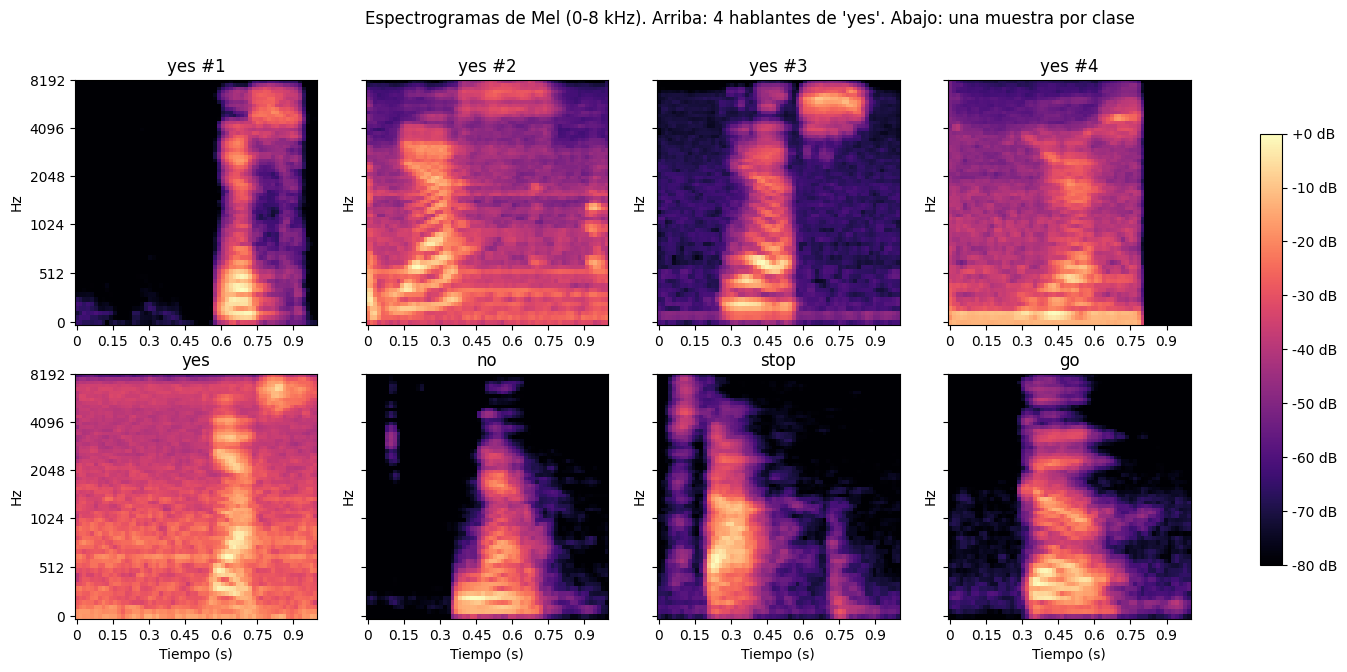

,panel,archivo,útil (ms),silencio inicial (ms),silencio final (ms),frecuencia central (Hz)
0,yes #1,yes/a55105d0_nohash_0.wav,368,576,64,415
1,yes #2,yes/b0bad4a9_nohash_1.wav,1008,0,0,727
2,yes #3,yes/78622c2b_nohash_0.wav,608,256,144,1097
3,yes #4,yes/2e7fac30_nohash_0.wav,816,0,192,246
4,yes,yes/f42e234b_nohash_0.wav,1008,0,0,1252
5,no,no/499be02e_nohash_3.wav,400,352,256,281
6,stop,stop/017c4098_nohash_4.wav,720,80,208,770
7,go,go/bab36420_nohash_3.wav,656,304,48,456


In [8]:
HOP_VISUAL = 256
X_vis, y_vis, archivos_vis = mel_db[HOP_VISUAL]["train"]
# Centro de cada filtro de Mel: los extremos 0 Hz y 8 kHz son bordes, no centros
frecuencias_mel = librosa.mel_frequencies(n_mels=N_MELS + 2, fmin=0, fmax=SR / 2)[1:-1]
ms_por_frame = 1000 * HOP_VISUAL / SR


def mostrar_mel(espectro_db, eje):
    """Espectrograma en dB con eje de tiempo en segundos y eje de Mel en Hz (0-8 kHz)."""
    return librosa.display.specshow(espectro_db, sr=SR, hop_length=HOP_VISUAL, x_axis="time", y_axis="mel",
                                    fmax=SR / 2, cmap="magma", ax=eje, vmin=-80, vmax=0)


# Fila 1: 4 hablantes distintos de "yes". Fila 2: una muestra de cada clase
rng_vis = np.random.default_rng(42)
hablantes_vis = np.array([a.split("/")[1].split("_nohash_")[0] for a in archivos_vis])
yes_mezclados = rng_vis.permutation(np.where(y_vis == 0)[0])
_, primera_vez = np.unique(hablantes_vis[yes_mezclados], return_index=True)   # una grabación por hablante
indices_yes = yes_mezclados[np.sort(primera_vez)[:4]]
indices_clases = [rng_vis.choice(np.where(y_vis == c)[0]) for c in range(len(CLASES))]
seleccion = list(indices_yes) + indices_clases


def describir_espectrograma(espectro_db, umbral_db=-40):
    """Duración útil, silencios y frecuencia central de un espectrograma en dB."""
    activos = np.where(espectro_db.max(axis=0) > umbral_db)[0]
    inicio, fin = activos[0], activos[-1]
    energia = librosa.db_to_power(espectro_db[:, inicio:fin + 1]).sum(axis=1)
    return {
        "útil (ms)": round((fin - inicio + 1) * ms_por_frame),
        "silencio inicial (ms)": round(inicio * ms_por_frame),
        "silencio final (ms)": round((espectro_db.shape[1] - 1 - fin) * ms_por_frame),
        "frecuencia central (Hz)": round(float((energia * frecuencias_mel).sum() / energia.sum())),
    }


fig, ejes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
filas_tabla = []
for posicion, (eje, indice) in enumerate(zip(ejes.flat, seleccion)):
    titulo = f"{CLASES[y_vis[indice]]} #{posicion + 1}" if posicion < 4 else CLASES[y_vis[indice]]
    imagen = mostrar_mel(X_vis[indice], eje)
    eje.set_title(titulo)
    eje.set_xlabel("Tiempo (s)" if posicion >= 4 else "")
    filas_tabla.append({"panel": titulo, "archivo": archivos_vis[indice], **describir_espectrograma(X_vis[indice])})
fig.colorbar(imagen, ax=ejes, format="%+.0f dB", shrink=0.8)
fig.suptitle("Espectrogramas de Mel (0-8 kHz). Arriba: 4 hablantes de 'yes'. Abajo: una muestra por clase")
fig.savefig(carpeta_figuras / "ej1_01_espectrogramas.png", dpi=120, bbox_inches="tight")
plt.show()
pd.DataFrame(filas_tabla)

**Análisis de los espectrogramas.**

- **Eje horizontal (tiempo).** El audio dura 1 s, pero la palabra ocupa solo una
  parte. En los cuatro `yes` de arriba, la parte útil dura entre 368 y 1008 ms, y
  la palabra empieza entre 0 y 576 ms. El resto es silencio (negro) o ruido de
  fondo (violeta).
- **Eje vertical (frecuencia de Mel).** Las vocales tienen la energía por debajo
  de 1 kHz, en armónicos paralelos (rayas horizontales). La separación entre las
  rayas es la frecuencia fundamental de la voz, y cambia con el hablante. Las
  fricativas (la "s" de `yes` y de `stop`) tienen energía entre 4 y 8 kHz, sin
  armónicos.
- **Color (energía en dB).** El color claro es energía alta, cerca de 0 dB. El
  negro es −80 dB, el piso del cálculo. El fondo cambia mucho entre grabaciones:
  `yes #1` tiene silencio negro, `yes #2` y el `yes` de abajo tienen ruido en todas
  las frecuencias, y `yes #4` tiene una banda fuerte por debajo de 100 Hz (un
  zumbido).
- **Misma clase.** Los cuatro `yes` tienen el mismo patrón: una vocal con
  armónicos que suben (la transición de /j/ a /e/), y después la "s" como un
  bloque claro entre 4 y 8 kHz. Cambian la posición en el tiempo, la duración, el
  tono, el volumen y el ruido. En `yes #4` la "s" es débil. Por eso el modelo
  necesita invariancia a desplazamientos en el tiempo y robustez al ruido.
- **Clases distintas.** `stop` es la clase más distinta. Empieza con la "s"
  (energía hasta 8 kHz entre 0 y 0.2 s), tiene un silencio corto por el cierre de
  la "t", y después la vocal entre 300 y 1500 Hz. `no` y `go` tienen casi toda la
  energía por debajo de 2 kHz y no tienen fricativa. Las dos terminan con la misma
  vocal /oʊ/. Solo la consonante inicial las separa: la nasal /n/ contra la
  oclusiva /g/, que dura pocos frames. Esperamos que `no` y `go` sean el par más
  confundido.

### 3.4 Espectrograma promedio por clase

Un ejemplo individual tiene ruido y variaciones del hablante. El promedio de
todos los espectrogramas de train de una clase muestra el patrón común. Sirve
para responder si las clases se distinguen por la distribución temporal y
frecuencial de la energía.

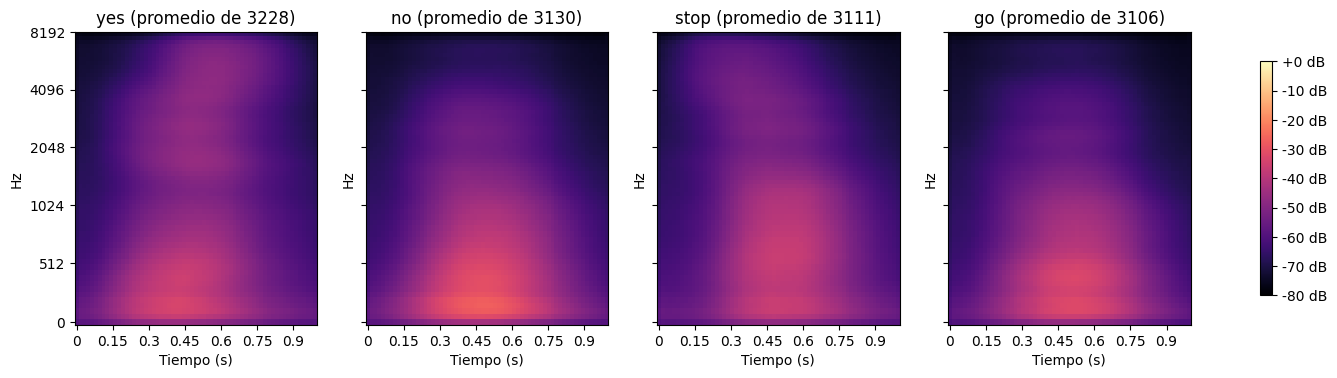

In [9]:
fig, ejes = plt.subplots(1, len(CLASES), figsize=(18, 3.8), sharey=True)
for indice_clase, eje in enumerate(ejes):
    imagen = mostrar_mel(X_vis[y_vis == indice_clase].mean(axis=0), eje)
    eje.set_title(f"{CLASES[indice_clase]} (promedio de {np.sum(y_vis == indice_clase)})")
    eje.set_xlabel("Tiempo (s)")
fig.colorbar(imagen, ax=ejes, format="%+.0f dB", shrink=0.8)
fig.savefig(carpeta_figuras / "ej1_02_promedio_por_clase.png", dpi=120, bbox_inches="tight")
plt.show()

Los promedios confirman el análisis de la sección 3.3:

- `yes` es la única clase con energía entre 2 y 8 kHz en la segunda mitad del
  segundo. Es la "s" final.
- `stop` tiene energía en altas frecuencias al principio (la "s" inicial). Su
  vocal está más arriba que las otras, entre 500 y 1000 Hz.
- `no` y `go` tienen promedios casi iguales: energía por debajo de 1 kHz en el
  mismo intervalo de tiempo. `no` concentra un poco más de energía en la banda más
  baja, por el murmullo nasal de la /n/.
- Todos los promedios están borrosos en el tiempo, porque la palabra empieza en
  posiciones distintas. La energía está centrada entre 0.3 y 0.7 s, con mucha
  dispersión.

## 4. Segmentación con ventana deslizante

### 4.1 Ventanas y comprobación

`extraer_ventanas` es la función del enunciado. Para entrenar usamos una versión
vectorizada, `a_ventanas`, que corta un batch completo en la GPU con
`Tensor.unfold`. La celda comprueba que las dos versiones dan el mismo resultado.

La cantidad de ventanas es `N = (T - W) // hop + 1`. Con los valores del
enunciado (`W=16`, `hop=8`) y `hop_length=512`, `T = 32` da solo **N = 3**
ventanas. Es una secuencia muy corta para una RNN. Con `hop_length=256`,
`T = 63` da **N = 6** ventanas, cada una de 256 ms. El experimento E2 mide el
efecto de este cambio.

In [10]:
def extraer_ventanas(mel, window_size=16, hop=8):
    """
    mel: array (F, T)
    window_size: ancho de cada ventana en frames temporales
    hop: desplazamiento entre ventanas (hop < window_size -> solapamiento)

    Retorna: array (N, F, window_size) con N ventanas
    """
    F, T = mel.shape
    ventanas = []
    for start in range(0, T - window_size + 1, hop):
        ventana = mel[:, start : start + window_size]  # (F, W)
        ventanas.append(ventana)
    return np.stack(ventanas)  # (N, F, W)


def a_ventanas(batch_mel, window_size, hop):
    """(B, F, T) -> (B, N, 1, F, W), la entrada que espera la CRNN."""
    ventanas = batch_mel.unfold(dimension=2, size=window_size, step=hop)  # (B, F, N, W)
    return ventanas.permute(0, 2, 1, 3).unsqueeze(2).contiguous()


# Las dos versiones tienen que coincidir
for hop in HOPS_STFT:
    ejemplo = datos_norm[hop]["train"][0][:5]
    lento = np.stack([extraer_ventanas(m, 16, 8) for m in ejemplo])          # (5, N, F, W)
    rapido = a_ventanas(torch.from_numpy(ejemplo), 16, 8).squeeze(2).numpy()  # (5, N, F, W)
    assert np.array_equal(lento, rapido)
    print(f"hop_length={hop}: T={ejemplo.shape[2]} -> ventanas {rapido.shape[1:]} (N, F, W). Coinciden.")

hop_length=512: T=32 -> ventanas (3, 64, 16) (N, F, W). Coinciden.
hop_length=256: T=63 -> ventanas (6, 64, 16) (N, F, W). Coinciden.


Las dos implementaciones dan arreglos idénticos. Cada ventana tiene forma
`(64, 16)`: frecuencia en la altura y tiempo en el ancho, como pide el enunciado.

### 4.2 Ventanas sobre un espectrograma

La figura marca las ventanas sobre un ejemplo de `stop`, como la Figura 3 del
enunciado. Con `W=16` y `hop=8`, el solapamiento es del 50 %. Cada transición
fonética aparece en al menos dos ventanas consecutivas.

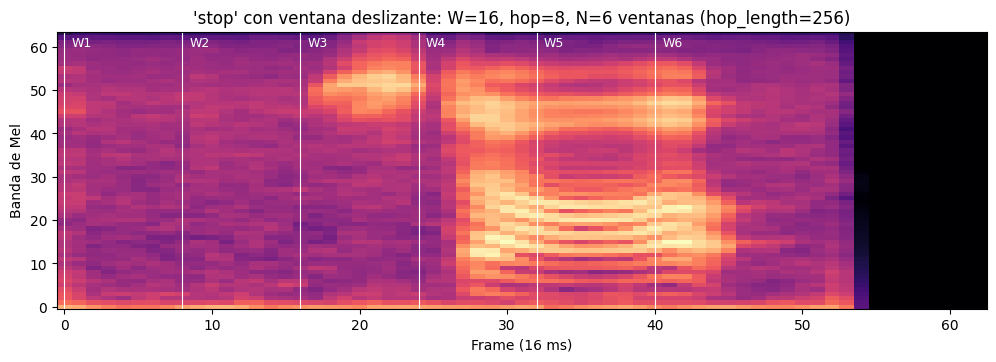

In [11]:
indice_stop = np.where(y_vis == CLASES.index("stop"))[0][0]
fig, eje = plt.subplots(figsize=(12, 3.6))
eje.imshow(X_vis[indice_stop], origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0)
T_vis = X_vis.shape[2]
for numero, inicio in enumerate(range(0, T_vis - 16 + 1, 8)):
    eje.axvline(inicio, color="white", lw=0.8)
    eje.text(inicio + 0.5, N_MELS - 4, f"W{numero + 1}", color="white", fontsize=9)
eje.set_xlabel("Frame (16 ms)")
eje.set_ylabel("Banda de Mel")
eje.set_title(f"'stop' con ventana deslizante: W=16, hop=8, N={(T_vis - 16) // 8 + 1} ventanas (hop_length=256)")
fig.savefig(carpeta_figuras / "ej1_03_ventanas.png", dpi=120, bbox_inches="tight")
plt.show()

Cada línea blanca marca el inicio de una ventana. Las ventanas cubren el segundo
completo, incluido el silencio, y la RNN recibe una ventana por paso.

## 5. Arquitectura CRNN

### 5.1 Encoder CNN y CRNN parametrizables

Partimos de `CNNEncoder` y `CRNN` del enunciado y agregamos parámetros para los
experimentos:

- **CNN**: cantidad de bloques (`filtros`), tamaño de kernel y `Dropout2d` dentro
  del encoder. Cada bloque es Conv → ReLU → BatchNorm → MaxPool(2), como en el
  enunciado.
- **RNN**: celda `GRU` o `LSTM`, capas, unidades, bidireccional o no.
- **Agregación**: `"ultimo"` (último paso de la secuencia) o `"promedio"`
  (average pooling sobre todos los pasos).

El tamaño de salida de la CNN se calcula con un tensor de prueba. Así sirve para
cualquier cantidad de bloques.

Un detalle de la versión bidireccional con `"ultimo"`: en `x[:, -1, :]` la mitad
hacia adelante ya leyó toda la secuencia, pero la mitad hacia atrás solo leyó la
última ventana. El promedio usa todos los pasos de las dos direcciones.

In [12]:
class CNNEncoder(nn.Module):
    """Procesa una sola ventana (batch, 1, F, W) -> vector (batch, dim_salida)."""

    def __init__(self, n_mels=64, window_size=16, filtros=(32, 64), kernel=3, dropout=0.0, dim_salida=128):
        super().__init__()
        capas, canales = [], 1
        for n_filtros in filtros:
            capas += [
                nn.Conv2d(canales, n_filtros, kernel_size=kernel, padding=kernel // 2),
                nn.ReLU(), nn.BatchNorm2d(n_filtros),
                nn.MaxPool2d(2),                       # divide F y W por 2
            ]
            if dropout > 0:
                capas.append(nn.Dropout2d(dropout))
            canales = n_filtros
        self.cnn = nn.Sequential(*capas)
        # calcular el tamaño de la salida aplanada con un tensor de prueba
        with torch.no_grad():
            self.out_size = self.cnn(torch.zeros(1, 1, n_mels, window_size)).numel()
        self.fc = nn.Linear(self.out_size, dim_salida)

    def forward(self, x):
        x = self.cnn(x)          # (batch, C, F', W')
        x = x.flatten(1)         # (batch, out_size)
        return self.fc(x)        # (batch, dim_salida)


class CRNN(nn.Module):
    def __init__(self, n_mels=64, window_size=16, n_classes=4, filtros=(32, 64), kernel=3,
                 dropout_cnn=0.0, celda="GRU", rnn_hidden=128, rnn_layers=2,
                 bidireccional=True, agregacion="ultimo"):
        super().__init__()
        self.agregacion = agregacion
        self.encoder = CNNEncoder(n_mels, window_size, filtros, kernel, dropout_cnn, dim_salida=128)
        tipo_rnn = {"GRU": nn.GRU, "LSTM": nn.LSTM}[celda]
        self.rnn = tipo_rnn(
            input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True,
            bidirectional=bidireccional, dropout=0.3 if rnn_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(rnn_hidden * (2 if bidireccional else 1), n_classes)

    def forward(self, x):
        # x: (batch, N, 1, F, W) -- N ventanas por muestra
        batch, N, C, F, W = x.shape
        x = x.view(batch * N, C, F, W)       # procesar todas las ventanas juntas
        x = self.encoder(x)                  # (batch*N, 128)
        x = x.view(batch, N, -1)             # (batch, N, 128) -- restaurar la secuencia
        x, _ = self.rnn(x)                   # (batch, N, hidden * direcciones)
        x = x[:, -1, :] if self.agregacion == "ultimo" else x.mean(dim=1)
        return self.fc(x)


# Prueba de shapes con la configuración del enunciado
modelo_prueba = CRNN(n_classes=len(CLASES))
entrada_prueba = torch.zeros(8, 3, 1, N_MELS, 16)
salida_prueba = modelo_prueba(entrada_prueba)
assert salida_prueba.shape == (8, len(CLASES))
print("Entrada", tuple(entrada_prueba.shape), "-> salida", tuple(salida_prueba.shape))
print("Salida aplanada de la CNN:", modelo_prueba.encoder.out_size)
print(f"Parámetros: {sum(p.numel() for p in modelo_prueba.parameters()):,}")

Entrada (8, 3, 1, 64, 16) -> salida (8, 4)
Salida aplanada de la CNN: 4096
Parámetros: 1,039,044


La red acepta un batch de 8 muestras con 3 ventanas cada una y devuelve 8 vectores
de 4 logits. La salida aplanada de la CNN es `64 · 16 · 4 = 4096`, igual que en el
enunciado (`64 * (n_mels // 4) * (window_size // 4)`).

## 6. Entrenamiento

### 6.1 Función de entrenamiento con checkpoints

Decisiones, según la sección 1.4 del enunciado:

- **Pérdida y optimizador**: `CrossEntropyLoss` y `Adam` (lr = 1e-3).
- **Scheduler**: `ReduceLROnPlateau` sobre la loss de validación. Divide el lr
  por 2 si la loss no mejora en 2 épocas.
- **Gradient clipping** de norma 1: limita los gradientes que explotan en una
  RNN (Unidad 11).
- **Early stopping** sobre la accuracy de validación, con paciencia de 5 épocas.
  Guardamos los pesos de la mejor época.
- **Mezcla de train con semilla `42 + época`**. Un entrenamiento retomado desde un
  checkpoint ve los mismos batches que uno sin cortes.
- **Checkpoint en cada época**, con el formato del enunciado más el scheduler, el
  historial, los mejores pesos, el estado del generador aleatorio (para el dropout) y
  la configuración. Un checkpoint con otra configuración no se usa. Si el archivo existe, el entrenamiento sigue
  desde la época siguiente. Si el experimento terminó, solo se cargan sus
  resultados.

Los espectrogramas normalizados están en memoria como tensores. El corte en
ventanas se hace por batch en el dispositivo, con `a_ventanas`.

In [13]:
MAX_EPOCAS = 2 if SMOKE else 20
PACIENCIA = 5
criterio = nn.CrossEntropyLoss()


def crear_loader(hop, split, batch_size, mezclar):
    X, y = datos_norm[hop][split]
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    generador = torch.Generator().manual_seed(42)
    # El BatchSampler pide un batch entero por índice: un solo indexado por batch, no uno por muestra.
    # El DataLoader y el sampler comparten el generador, como con shuffle=True: misma permutación.
    muestreo = RandomSampler(dataset, generator=generador) if mezclar else SequentialSampler(dataset)
    return DataLoader(dataset, sampler=BatchSampler(muestreo, batch_size, drop_last=False), batch_size=None,
                      generator=generador)


def crear_modelo(cfg):
    return CRNN(N_MELS, cfg["window_size"], len(CLASES), cfg["filtros"], cfg["kernel"],
                cfg["dropout_cnn"], cfg["celda"], cfg["rnn_hidden"], cfg["rnn_layers"],
                cfg["bidireccional"], cfg["agregacion"]).to(device)


def correr_epoca(modelo, loader, cfg, optimizador=None):
    """Una pasada por el loader. Si hay optimizador, entrena. Devuelve (loss, accuracy)."""
    modelo.train(optimizador is not None)
    suma_loss = torch.zeros((), dtype=torch.float64, device=device)
    aciertos, total = torch.zeros((), dtype=torch.int64, device=device), 0
    with torch.set_grad_enabled(optimizador is not None):
        for X, y in loader:
            X = a_ventanas(X.to(device), cfg["window_size"], cfg["window_hop"])
            y = y.to(device)
            logits = modelo(X)
            loss = criterio(logits, y)
            if optimizador is not None:
                optimizador.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            # Acumular en el dispositivo: un solo .item() por época, no dos por batch
            suma_loss += loss.detach().double() * len(y)
            aciertos += (logits.argmax(1) == y).sum()
            total += len(y)
    return suma_loss.item() / total, aciertos.item() / total


def predecir(modelo, loader, cfg):
    """Logits de todo el loader, en el orden del loader."""
    modelo.eval()
    with torch.no_grad():
        return torch.cat([modelo(a_ventanas(X.to(device), cfg["window_size"], cfg["window_hop"])).cpu()
                          for X, _ in loader])


def entrenar_experimento(nombre, cfg):
    ruta = carpeta_ckpt / f"{nombre}.pth"
    set_seed(42)
    modelo = crear_modelo(cfg)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=cfg["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=2)
    estado = {"epoch": -1, "historia": {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "segundos")},
              "mejor_acc": -1.0, "mejor_epoca": -1, "mejor_estado": None, "sin_mejora": 0}

    # Retomar desde el checkpoint, si existe
    checkpoint = torch.load(ruta, map_location=device, weights_only=False) if ruta.exists() else None
    if checkpoint is not None and checkpoint["cfg"] != cfg:
        print(f"{nombre}: el checkpoint tiene otra configuración. Se entrena de cero y se reemplaza.")
        checkpoint = None
    if checkpoint is not None:
        modelo.load_state_dict(checkpoint["model_state_dict"])
        optimizador.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        estado = checkpoint["estado"]
        # El generador global define las máscaras de dropout: se retoma desde donde quedó
        torch.set_rng_state(checkpoint["rng_torch"])
        if torch.cuda.is_available() and checkpoint["rng_cuda"] is not None:
            torch.cuda.set_rng_state_all(checkpoint["rng_cuda"])
        if estado["sin_mejora"] >= PACIENCIA or estado["epoch"] + 1 >= MAX_EPOCAS:
            print(f"{nombre}: terminado antes (mejor época {estado['mejor_epoca'] + 1}). Se cargan los resultados.")
        else:
            print(f"{nombre}: se retoma desde la época {estado['epoch'] + 2}")

    loader_train = crear_loader(cfg["hop_length"], "train", cfg["batch_size"], True)
    loader_val = crear_loader(cfg["hop_length"], "val", 256, False)
    for epoca in range(estado["epoch"] + 1, MAX_EPOCAS):
        if estado["sin_mejora"] >= PACIENCIA:   # early stopping
            break
        inicio = time.time()
        # Semilla de la mezcla por época: un entrenamiento retomado mezcla igual que uno sin cortes
        loader_train.generator.manual_seed(42 + epoca)
        train_loss, train_acc = correr_epoca(modelo, loader_train, cfg, optimizador)
        val_loss, val_acc = correr_epoca(modelo, loader_val, cfg)
        scheduler.step(val_loss)
        historia = estado["historia"]
        for clave, valor in dict(train_loss=train_loss, train_acc=train_acc, val_loss=val_loss, val_acc=val_acc,
                                 lr=optimizador.param_groups[0]["lr"], segundos=time.time() - inicio).items():
            historia[clave].append(valor)
        # Early stopping sobre la accuracy de validación
        if val_acc > estado["mejor_acc"]:
            estado.update(mejor_acc=val_acc, mejor_epoca=epoca, sin_mejora=0,
                          mejor_estado={k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()})
        else:
            estado["sin_mejora"] += 1
        estado["epoch"] = epoca
        print(f"{nombre} ep {epoca + 1:2d} | train {train_loss:.3f} / {train_acc:.3f} | "
              f"val {val_loss:.3f} / {val_acc:.3f} | {historia['segundos'][-1]:.1f} s")
        torch.save({"epoch": epoca, "model_state_dict": modelo.state_dict(),
                    "optimizer_state_dict": optimizador.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "loss": train_loss, "cfg": cfg, "estado": estado, "rng_torch": torch.get_rng_state(),
                    "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, ruta)

    modelo.load_state_dict(estado["mejor_estado"])
    return modelo, estado

La función entrena, guarda y retoma. Para un experimento terminado no vuelve a
entrenar: carga los mejores pesos y el historial del checkpoint.

### 6.2 Experimentos

La línea base E1 es la arquitectura del enunciado. Cada experimento de E2 a E5
cambia **una sola** dimensión respecto de E1. Así, cada diferencia de accuracy
tiene una sola causa.

| Exp. | Cambio respecto de E1 | Dimensión del enunciado |
|---|---|---|
| E1 | Ninguno: 2 bloques 32/64, kernel 3, W=16 hop=8, BiGRU 2×128, último estado | Línea base |
| E2 | `hop_length=256`: T=63 y N=6 ventanas (en lugar de 3) | Ventana deslizante |
| E3 | LSTM en lugar de GRU | Tipo de celda |
| E4 | Average pooling sobre los pasos en lugar del último estado | Agregación |
| E5 | 3 bloques 32/64/128 con Dropout2d 0.2 | Profundidad, filtros y dropout de la CNN |
| E6 | Todos los cambios de E2 a E5 que mejoran la val de E1 | Combinación |

E6 se arma de forma automática después de E1 a E5, solo con la accuracy de
validación. Test no interviene en ninguna decisión.

In [14]:
CONFIG_BASE = dict(hop_length=512, window_size=16, window_hop=8, filtros=(32, 64), kernel=3,
                   dropout_cnn=0.0, celda="GRU", rnn_hidden=128, rnn_layers=2,
                   bidireccional=True, agregacion="ultimo", lr=1e-3, batch_size=64)
CAMBIOS = {
    "E1_base": {},
    "E2_hop256": {"hop_length": 256},
    "E3_lstm": {"celda": "LSTM"},
    "E4_promedio": {"agregacion": "promedio"},
    "E5_cnn3_dropout": {"filtros": (32, 64, 128), "dropout_cnn": 0.2},
}

modelos, estados, configs = {}, {}, {}
for nombre, cambio in CAMBIOS.items():
    configs[nombre] = {**CONFIG_BASE, **cambio}
    modelos[nombre], estados[nombre] = entrenar_experimento(nombre, configs[nombre])

# E6: combinar los cambios que mejoran la accuracy de validación de E1
acc_base = estados["E1_base"]["mejor_acc"]
cambios_e6 = {}
for nombre, cambio in CAMBIOS.items():
    if cambio and estados[nombre]["mejor_acc"] > acc_base:
        cambios_e6.update(cambio)
print("Cambios que mejoran la val de E1:", cambios_e6 or "ninguno")
if cambios_e6 and cambios_e6 not in CAMBIOS.values():
    CAMBIOS["E6_combinado"] = cambios_e6
    configs["E6_combinado"] = {**CONFIG_BASE, **cambios_e6}
    modelos["E6_combinado"], estados["E6_combinado"] = entrenar_experimento("E6_combinado", configs["E6_combinado"])
else:
    print("E6 no se entrena: la combinación es igual a un experimento que ya existe.")

E1_base ep  1 | train 0.372 / 0.845 | val 0.237 / 0.913 | 10.3 s
E1_base ep  2 | train 0.166 / 0.937 | val 0.195 / 0.927 | 6.8 s
E1_base ep  3 | train 0.123 / 0.955 | val 0.161 / 0.944 | 6.8 s
E1_base ep  4 | train 0.098 / 0.963 | val 0.214 / 0.937 | 6.9 s
E1_base ep  5 | train 0.083 / 0.971 | val 0.123 / 0.958 | 6.9 s
E1_base ep  6 | train 0.062 / 0.978 | val 0.127 / 0.963 | 6.9 s
E1_base ep  7 | train 0.055 / 0.980 | val 0.105 / 0.969 | 6.9 s
E1_base ep  8 | train 0.056 / 0.979 | val 0.113 / 0.962 | 7.0 s
E1_base ep  9 | train 0.046 / 0.984 | val 0.179 / 0.951 | 7.0 s
E1_base ep 10 | train 0.048 / 0.983 | val 0.127 / 0.964 | 7.0 s
E1_base ep 11 | train 0.025 / 0.991 | val 0.126 / 0.965 | 7.1 s
E1_base ep 12 | train 0.016 / 0.994 | val 0.131 / 0.965 | 7.1 s
E2_hop256 ep  1 | train 0.338 / 0.863 | val 0.226 / 0.923 | 14.5 s
E2_hop256 ep  2 | train 0.152 / 0.946 | val 0.159 / 0.935 | 14.8 s
E2_hop256 ep  3 | train 0.110 / 0.962 | val 0.103 / 0.964 | 14.8 s
E2_hop256 ep  4 | train 0.088 

> **Resultado.** Los seis experimentos terminaron en Colab con GPU.

| Exp. | Épocas | Mejor época | Acc. val | s/época |
|---|---|---|---|---|
| E1 | 12 | 7 | 0.9685 | 7.2 |
| E2 | 16 | 11 | 0.9738 | 14.5 |
| E3 | 16 | 11 | 0.9685 | 7.3 |
| E4 | 19 | 14 | 0.9784 | 7.2 |
| E5 | 18 | 13 | 0.9744 | 7.6 |
| E6 | 16 | 11 | 0.9797 | 15.1 |

- El early stopping cortó todos los experimentos antes del límite de 20 épocas.
- E3 (LSTM) empata con E1 en validación, así que no entra en E6. E6 combina
  `hop_length=256`, el promedio de los estados y la CNN de 3 bloques con dropout.
- Con `hop_length=256` cada época tarda el doble. La CNN procesa 6 ventanas por
  audio en lugar de 3, y la RNN recibe una secuencia el doble de larga.
- Los seis experimentos tardaron unos 16 minutos en total.

### 6.3 Curvas de entrenamiento

Para cada experimento, loss y accuracy de train y de validación por época. La
línea punteada marca la mejor época según la accuracy de validación.

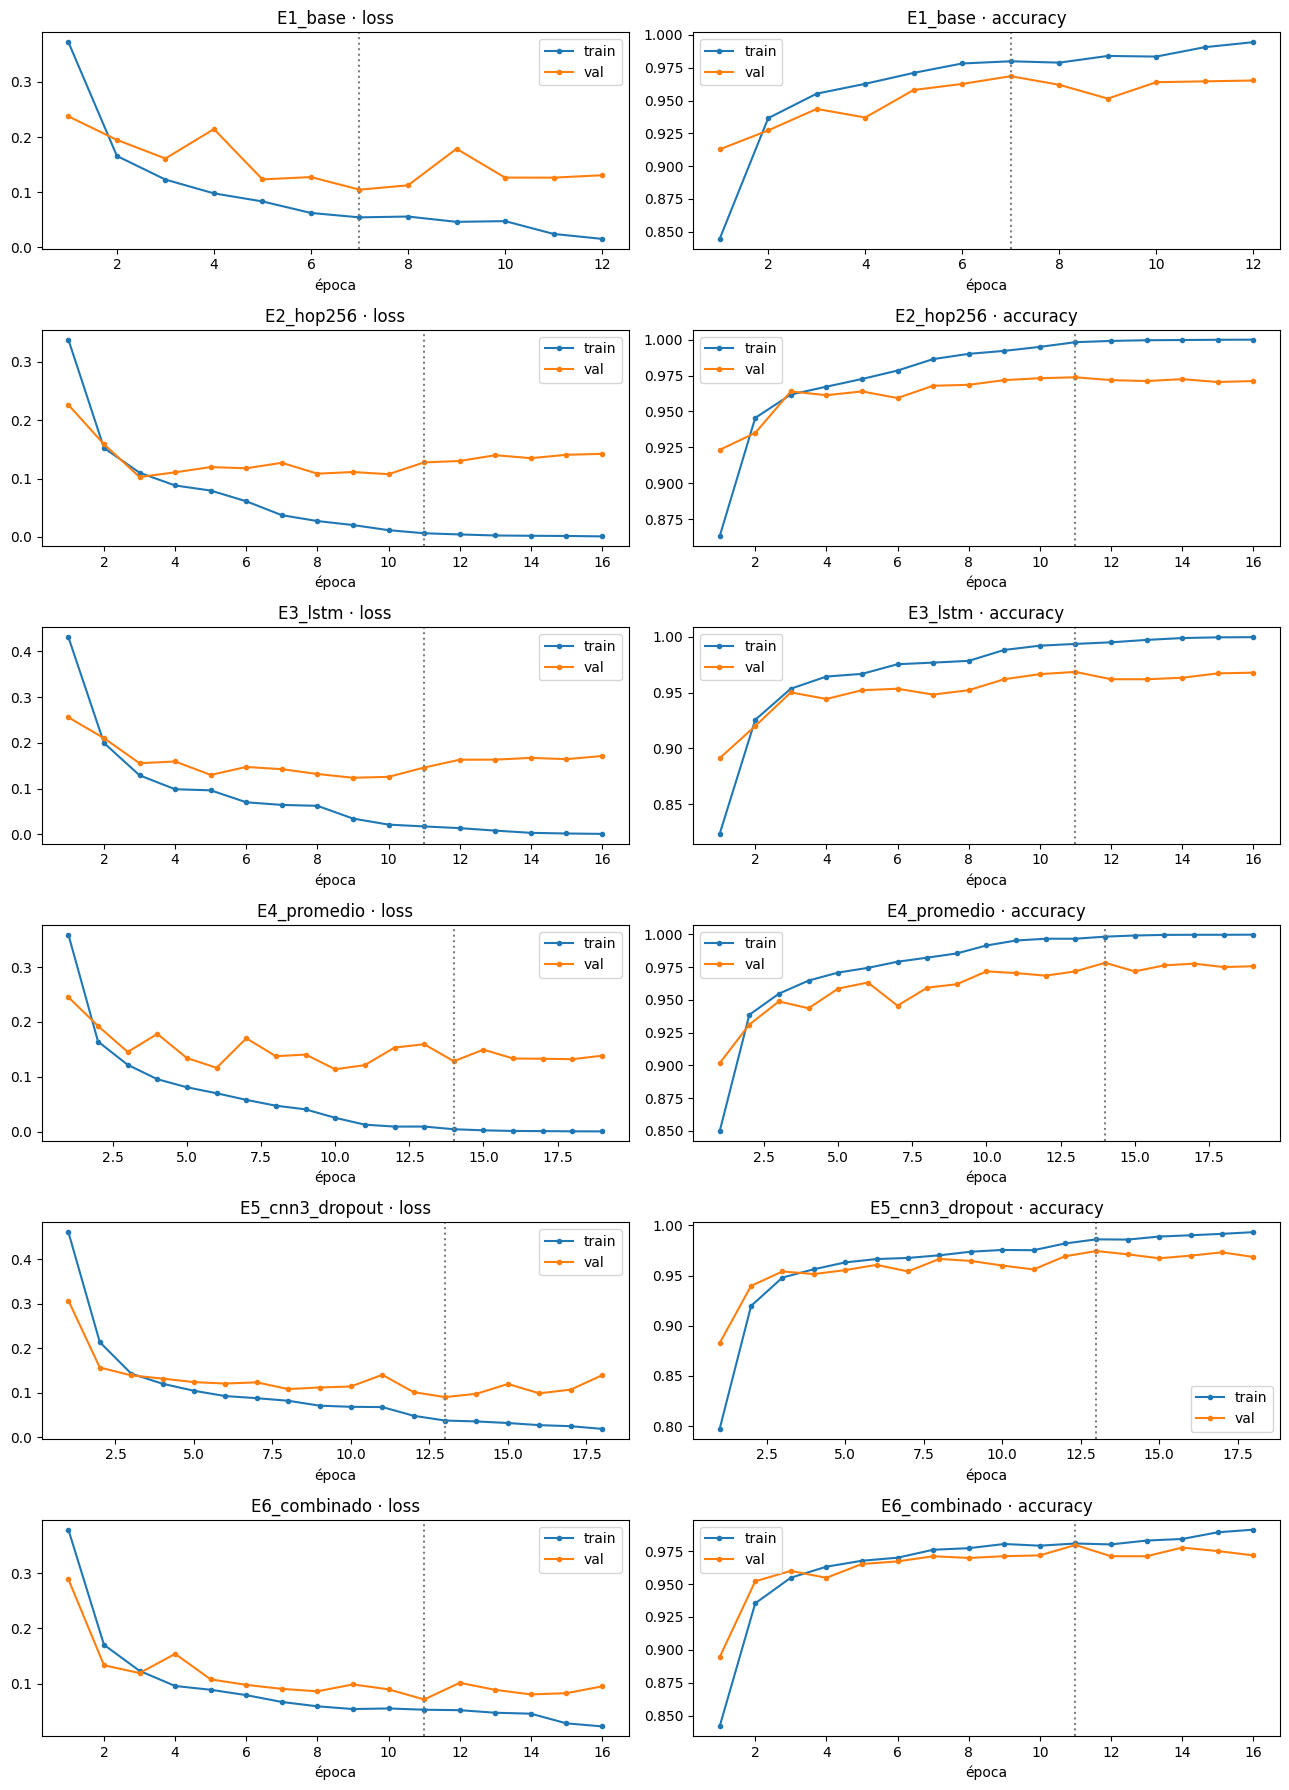

In [15]:
fig, ejes = plt.subplots(len(estados), 2, figsize=(13, 3.0 * len(estados)), squeeze=False)
for fila, (nombre, estado) in enumerate(estados.items()):
    historia = estado["historia"]
    epocas = np.arange(1, len(historia["train_loss"]) + 1)
    for columna, metrica in enumerate(("loss", "acc")):
        eje = ejes[fila, columna]
        eje.plot(epocas, historia[f"train_{metrica}"], "o-", ms=3, label="train")
        eje.plot(epocas, historia[f"val_{metrica}"], "o-", ms=3, label="val")
        eje.axvline(estado["mejor_epoca"] + 1, color="gray", ls=":")
        eje.set_title(f"{nombre} · {'loss' if metrica == 'loss' else 'accuracy'}")
        eje.set_xlabel("época")
        eje.legend()
fig.tight_layout()
fig.savefig(carpeta_figuras / "ej1_04_curvas.png", dpi=110, bbox_inches="tight")
plt.show()

> **Resultado.**

- En E1 a E4, la accuracy de train llega a 0.99-1.00 y la loss de train baja casi
  a 0. La loss de validación deja de bajar entre las épocas 3 y 9, y después sube.
  Por ejemplo, en E3 sube de 0.12 a 0.17. Es sobreajuste: el modelo memoriza train,
  y sus errores en validación tienen cada vez más confianza. La accuracy de
  validación casi no cambia, porque el sobreajuste afecta más a la confianza que a
  la clase elegida.
- En E5 y E6, el dropout de la CNN frena el sobreajuste. La accuracy de train
  queda en 0.98-0.99, y las curvas de train y de validación están más cerca. E6
  tiene la menor loss de validación de todos: 0.071 en la época 11.
- Las curvas de validación oscilan de una época a otra, por ejemplo E1 en la
  época 9. Con 1525 audios de validación, una diferencia de 0.01 son unos 15
  audios.

### 6.4 Selección del mejor modelo y evaluación en test

El mejor modelo es el de mayor accuracy de **validación**. Después de esa
elección evaluamos test una sola vez, para todos los experimentos, para completar
la tabla comparativa del enunciado. La accuracy de test no cambia la elección.

In [16]:
def describir_cfg(cfg):
    cnn = f"{len(cfg['filtros'])} bloques {'/'.join(map(str, cfg['filtros']))}, k={cfg['kernel']}"
    if cfg["dropout_cnn"]:
        cnn += f", drop {cfg['dropout_cnn']}"
    rnn = (f"{'Bi' if cfg['bidireccional'] else ''}{cfg['celda']} {cfg['rnn_layers']}×{cfg['rnn_hidden']}, "
           f"{'último' if cfg['agregacion'] == 'ultimo' else 'promedio'}")
    T = 1 + SR // cfg["hop_length"]
    ventana = f"W={cfg['window_size']}, hop={cfg['window_hop']} (T={T}, N={(T - cfg['window_size']) // cfg['window_hop'] + 1})"
    return cnn, ventana, rnn


mejor_nombre = max(estados, key=lambda n: estados[n]["mejor_acc"])
print("Mejor modelo según validación:", mejor_nombre)

filas = []
predicciones_test, acc_test_por_modelo = {}, {}
for nombre, modelo in modelos.items():
    cfg = configs[nombre]
    logits = predecir(modelo, crear_loader(cfg["hop_length"], "test", 256, False), cfg)
    predicciones_test[nombre] = logits
    acc_test = (logits.argmax(1).numpy() == datos_norm[cfg["hop_length"]]["test"][1]).mean()
    acc_test_por_modelo[nombre] = acc_test
    cnn, ventana, rnn = describir_cfg(cfg)
    historia = estados[nombre]["historia"]
    filas.append({"Experimento": nombre, "CNN": cnn, "Ventana": ventana, "RNN": rnn,
                  "Parámetros": sum(p.numel() for p in modelo.parameters()),
                  "Mejor época": estados[nombre]["mejor_epoca"] + 1,
                  "s/época": round(float(np.mean(historia["segundos"])), 1),
                  "Acc. val": round(estados[nombre]["mejor_acc"], 4), "Acc. test": round(float(acc_test), 4)})

tabla_experimentos = pd.DataFrame(filas)
tabla_experimentos.to_csv(carpeta_figuras / "ej1_tabla_experimentos.csv", index=False)
# Error estándar de una accuracy en test, para saber qué diferencias son reales
n_test = len(datos_norm[512]["test"][1])
acc_mejor = acc_test_por_modelo[mejor_nombre]
print(f"n_test = {n_test}. Error estándar de la accuracy del mejor modelo: "
      f"{np.sqrt(acc_mejor * (1 - acc_mejor) / n_test):.4f}")
tabla_experimentos

Mejor modelo según validación: E6_combinado
n_test = 1637. Error estándar de la accuracy del mejor modelo: 0.0040


,Experimento,CNN,Ventana,RNN,Parámetros,Mejor época,s/época,Acc. val,Acc. test
0,E1_base,"2 bloques 32/64, k=3","W=16, hop=8 (T=32, N=3)","BiGRU 2×128, último",1039044,7,7.2,0.9685,0.9640
1,E2_hop256,"2 bloques 32/64, k=3","W=16, hop=8 (T=63, N=6)","BiGRU 2×128, último",1039044,11,14.5,0.9738,0.9750
2,E3_lstm,"2 bloques 32/64, k=3","W=16, hop=8 (T=32, N=3)","BiLSTM 2×128, último",1203908,11,7.3,0.9685,0.9688
3,E4_promedio,"2 bloques 32/64, k=3","W=16, hop=8 (T=32, N=3)","BiGRU 2×128, promedio",1039044,14,7.2,0.9784,0.9731
4,E5_cnn3_dropout,"3 bloques 32/64/128, k=3, drop 0.2","W=16, hop=8 (T=32, N=3)","BiGRU 2×128, último",851012,13,7.6,0.9744,0.9737
5,E6_combinado,"3 bloques 32/64/128, k=3, drop 0.2","W=16, hop=8 (T=63, N=6)","BiGRU 2×128, promedio",851012,11,15.1,0.9797,0.9737


> **Resultado.**

- E6 tiene la mejor accuracy de validación (0.9797) y es el modelo elegido. En test
  da 0.9737, con un error estándar de 0.004.
- El cambio que más ayuda es el promedio de los estados (E4: +0.010 en validación).
  Siguen la CNN de 3 bloques con dropout (E5: +0.006) y `hop_length=256` (E2:
  +0.005). La LSTM (E3) no mejora a la GRU, y tiene 16 % más parámetros.
- Las diferencias entre E2, E4, E5 y E6 son menores que dos errores estándar
  (0.008). Con este tamaño de validación y de test no se pueden ordenar con
  seguridad. Solo la diferencia entre E1 y los mejores modelos, de 0.01, es más
  grande que el ruido.
- En test, E2 da 0.9750, un poco más que E6. La diferencia es de 2 audios en 1637,
  y test no cambia la elección.

Por qué ayuda cada cambio:

- **Promedio de los estados (E4).** Con el último estado, la información de una
  palabra al principio del audio tiene que atravesar toda la secuencia. El
  promedio usa todos los pasos y depende menos de la posición de la palabra.
- **`hop_length=256` (E2).** Con 3 ventanas, la RNN casi no recibe una secuencia.
  Con 6 ventanas, cada frame dura 16 ms, y la red resuelve mejor las consonantes
  cortas, como la /g/ de `go`. El costo es el doble de tiempo por época.
- **3 bloques con dropout (E5).** El tercer pooling reduce la salida aplanada de
  4096 a 2048. Por eso el modelo baja de 1 039 044 a 851 012 parámetros. El
  dropout regulariza, como muestran las curvas.

## 7. Análisis del mejor modelo

### 7.1 Matriz de confusión en test

La matriz muestra cuántos ejemplos de cada clase real (filas) recibió cada clase
predicha (columnas). La celda imprime también precision y recall por clase, y
los pares más confundidos.

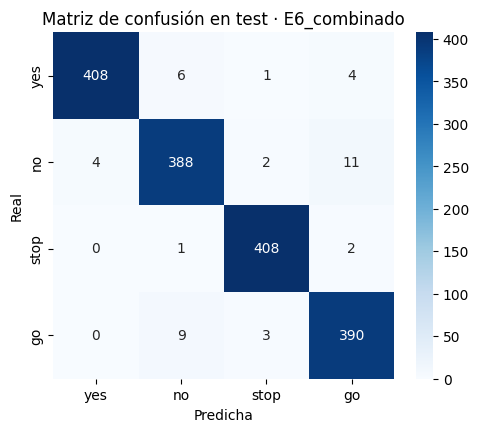

              precision    recall  f1-score   support

         yes      0.990     0.974     0.982       419
          no      0.960     0.958     0.959       405
        stop      0.986     0.993     0.989       411
          go      0.958     0.970     0.964       402

    accuracy                          0.974      1637
   macro avg      0.974     0.974     0.974      1637
weighted avg      0.974     0.974     0.974      1637

  no leído como go  : 11 casos (2.7%)
  go leído como no  : 9 casos (2.2%)
 yes leído como no  : 6 casos (1.4%)
  no leído como yes : 4 casos (1.0%)


In [17]:
y_test = datos_norm[configs[mejor_nombre]["hop_length"]]["test"][1]
y_pred = predicciones_test[mejor_nombre].argmax(1).numpy()
matriz = confusion_matrix(y_test, y_pred)

fig, eje = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=eje)
eje.set_xlabel("Predicha")
eje.set_ylabel("Real")
eje.set_title(f"Matriz de confusión en test · {mejor_nombre}")
fig.savefig(carpeta_figuras / "ej1_05_matriz_confusion.png", dpi=130, bbox_inches="tight")
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASES, digits=3))
confusiones = [(matriz[i, j], i, j) for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j]
for cantidad, i, j in sorted(confusiones, reverse=True)[:4]:
    print(f"{CLASES[i]:>4} leído como {CLASES[j]:<4}: {cantidad} casos ({cantidad / matriz[i].sum():.1%})")

**¿Qué comandos se confunden más? ¿Tiene sentido fonéticamente?**

> **Resultado.** Hay 43 errores en 1637 audios.

- **`no` y `go`** son el par más confundido: 11 `no` leídos como `go` y 9 `go`
  leídos como `no`. Son 20 errores, casi la mitad del total. Tiene sentido
  fonético. Las dos palabras terminan con la misma vocal /oʊ/, que ocupa la mayor
  parte del audio. Solo la consonante inicial las separa. La /n/ es nasal: es
  sonora, con energía baja y continua. La /g/ es oclusiva: un cierre corto y una
  explosión de 20 a 30 ms, es decir 1 o 2 frames con `hop_length=256`. Si el
  hablante pronuncia débil la consonante, o si hay ruido, solo queda la vocal.
- **`yes` leído como `no` (6 casos) o como `go` (4 casos).** No es una confusión
  fonética directa. En la sección 7.2, los errores de `yes` son audios cortados al
  final, sin la "s".
- **`stop`** tiene el mejor recall (0.993) y solo 3 errores. Es la única palabra
  que empieza con una fricativa y que tiene un silencio por el cierre de la /t/.
- Precision y recall son más bajos para `no` (0.960 y 0.958) y para `go` (0.958 y
  0.970). Es el mismo par.

### 7.2 Ejemplos de predicciones

Mostramos 6 ejemplos de test: 3 aciertos y 3 errores (si hay al menos 3
errores). Cada panel tiene el espectrograma, la etiqueta real, la predicción y
la probabilidad que el modelo le da a su predicción.

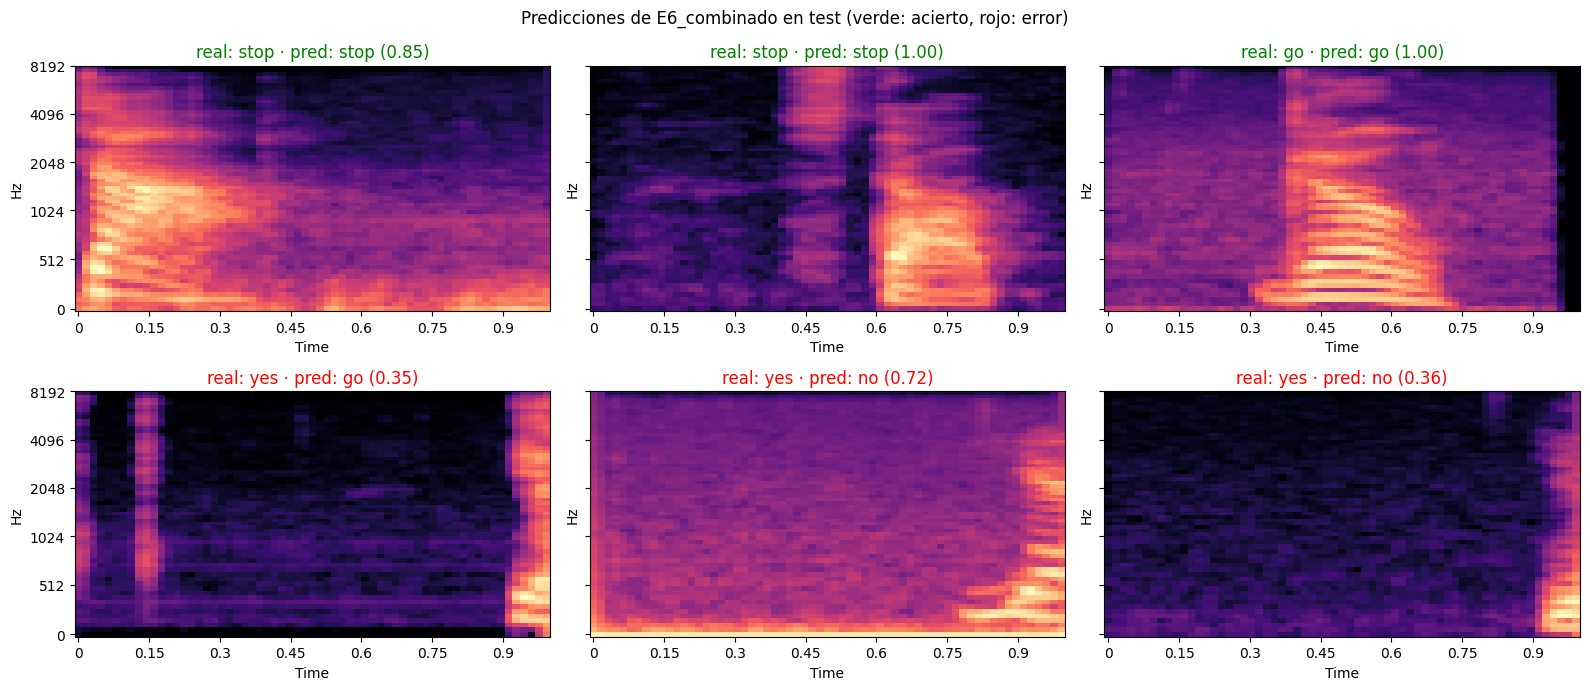

stop/9d4bab4f_nohash_1.wav          real stop pred stop probabilidades [0.028 0.085 0.854 0.033]
stop/18f8afd5_nohash_2.wav          real stop pred stop probabilidades [0. 0. 1. 0.]
go/7192fddc_nohash_0.wav            real go   pred go   probabilidades [0. 0. 0. 1.]
yes/0bac8a71_nohash_0.wav           real yes  pred go   probabilidades [0.134 0.259 0.26  0.348]
yes/6205088b_nohash_1.wav           real yes  pred no   probabilidades [0.19  0.716 0.006 0.088]
yes/18f8afd5_nohash_1.wav           real yes  pred no   probabilidades [0.196 0.36  0.184 0.26 ]


In [18]:
probabilidades = predicciones_test[mejor_nombre].softmax(1).numpy()
X_test_db, _, archivos_test = mel_db[HOP_VISUAL]["test"]
rng_ejemplos = np.random.default_rng(0)
aciertos_idx = np.where(y_pred == y_test)[0]
errores_idx = np.where(y_pred != y_test)[0]
n_errores = min(3, len(errores_idx))
n_aciertos = min(6 - n_errores, len(aciertos_idx))
elegidos = list(rng_ejemplos.choice(aciertos_idx, n_aciertos, replace=False))
elegidos += list(rng_ejemplos.choice(errores_idx, n_errores, replace=False)) if n_errores else []

fig, ejes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)
for eje, indice in zip(ejes.flat, elegidos):
    mostrar_mel(X_test_db[indice], eje)
    correcto = y_pred[indice] == y_test[indice]
    eje.set_title(f"real: {CLASES[y_test[indice]]} · pred: {CLASES[y_pred[indice]]} "
                  f"({probabilidades[indice, y_pred[indice]]:.2f})", color="green" if correcto else "red")
fig.suptitle(f"Predicciones de {mejor_nombre} en test (verde: acierto, rojo: error)")
fig.tight_layout()
fig.savefig(carpeta_figuras / "ej1_06_predicciones.png", dpi=120, bbox_inches="tight")
plt.show()
for indice in elegidos:
    print(f"{archivos_test[indice]:<35} real {CLASES[y_test[indice]]:<4} pred {CLASES[y_pred[indice]]:<4} "
          f"probabilidades {np.round(probabilidades[indice], 3)}")

> **Resultado.**

- Los tres aciertos tienen probabilidad alta, de 0.85 a 1.00. El primer `stop`
  tiene la palabra al principio y mucho ruido de fondo, y el modelo lo clasifica
  bien igual.
- Los tres errores son audios de `yes` en los que la palabra empieza cerca de
  0.9 s, y el final del segundo la corta. El modelo ve solo el inicio de la
  vocal, sin la "s" final, que es el rasgo que distingue a `yes`. Con solo 0.1 s
  de la palabra, el audio no tiene información suficiente para clasificarlo.
- En dos de los errores, la probabilidad máxima es baja (0.35 y 0.36): el modelo
  reparte la probabilidad entre varias clases. En el otro elige `no` con 0.72.
  Es un error con confianza alta sobre una entrada incompleta.
- Estos errores confirman que el modelo usa la "s" de `yes`, como anticipó el
  análisis de los espectrogramas.

## 8. Conclusiones

- La CRNN clasifica los 4 comandos con 97.4 % de accuracy en test (E6), con
  hablantes que no aparecen en train.
- Los espectrogramas muestran rasgos claros: la "s" de `yes` y de `stop`, y la
  vocal /oʊ/ que comparten `no` y `go`. Los errores aparecen donde esos rasgos
  faltan o se parecen: el par `no`/`go` y los audios cortados.
- Con el `hop_length=512` del enunciado, la RNN recibe solo 3 ventanas. Más
  resolución temporal (6 ventanas) y el promedio de los estados mejoran la
  validación. La LSTM no mejora a la GRU.
- El dropout en la CNN reduce el sobreajuste. Sin dropout, la accuracy de train
  llega a 1.00 y la loss de validación sube.
- Las diferencias entre las mejores configuraciones (menos de 0.01) son del orden
  del error estándar. Para ordenarlas hacen falta más datos o varias semillas por
  experimento.
- Una mejora posible es data augmentation con desplazamientos en el tiempo y
  ruido de fondo. Ataca las dos fuentes de variación que muestran los
  espectrogramas.